# 06 — Extended development evaluation

This independent supplement imports the **unchanged original models**. It adds
probability diagnostics and stronger cross-validation evidence; no third algorithm,
regularization, hyperparameter winner or operating threshold is introduced.

The original test scores in notebooks 02–04 were already viewed. Here we reproduce
the original outer partitions but use their development rows for all new fitting
and evaluation. Excluding test rows now does not undo that earlier exposure.
See [data contracts](../docs/DATASETS.md) and [overall findings](../docs/FINDINGS_AND_LIMITATIONS.md).


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from mlforge import LogisticRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
assert LogisticRegression.__module__ == "mlforge.logistic_regression"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## 1. Load the data and use a stratified split

Reserve 20% for testing with random_state=42. Stratification preserves
approximately the same class proportions in each subset. We will use
training rows for exploratory plots, scaling, and optimization.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X, y = dataset.data, dataset.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.Series({
    "Total observations": len(X),
    "Features": X.shape[1],
    "Training observations": len(X_train),
    "Test observations": len(X_test),
}, name="Dataset and split").to_frame())
class_counts = pd.DataFrame({
    "All": y.value_counts().sort_index(),
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
})
class_counts.index = ["Malignant (0)", "Benign (1)"]
display(class_counts)

,Dataset and split
Total observations,569
Features,30
Training observations,455
Test observations,114


,All,Train,Test
Malignant (0),212,170,42
Benign (1),357,285,72


## 2. Probability quality on a development validation split

The original 114-row test result in the original notebooks was already visible in the earlier project. We do not use it to choose new settings. Instead, divide the **455 original training rows** into an inner fitting subset and a stratified validation subset. Fit a new scaler and classifier only on inner fitting rows, with the same fixed learning rate and iteration count.

For this section, define the event as **malignancy**: `event = (y == 0)` and `p_event = predict_proba(...)[:, 0]`. A baseline predicts the inner-training malignant prevalence for every validation row. Log loss and Brier score evaluate probabilities; ROC AUC evaluates ranking. Lower probability losses and higher AUC are better. This validation experiment is descriptive and does not select a new model or threshold.

In [3]:
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score, roc_curve
from statistics import NormalDist

X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_train, y_train, test_size=.25, random_state=42, stratify=y_train
)
assert set(X_inner.index).isdisjoint(X_validation.index)
assert set(X_inner.index) | set(X_validation.index) == set(X_train.index)
assert (set(X_inner.index) | set(X_validation.index)).isdisjoint(X_test.index)
validation_scaler = StandardScaler().fit(X_inner)
np.testing.assert_allclose(validation_scaler.mean_, X_inner.mean().to_numpy())
assert validation_scaler.n_samples_seen_ == len(X_inner)
validation_model = LogisticRegression(learning_rate=.1, max_iter=2000).fit(
    validation_scaler.transform(X_inner), y_inner
)
event_validation = (y_validation.to_numpy() == 0).astype(int)
p_event = validation_model.predict_proba(validation_scaler.transform(X_validation))[:, 0]
p_prevalence = np.full(len(y_validation), float((y_inner == 0).mean()))
probability_results = pd.DataFrame([
    {"Predictor": label, "Validation rows": len(y_validation),
     "Log loss": log_loss(event_validation, p, labels=[0, 1]),
     "Brier score": brier_score_loss(event_validation, p),
     "ROC AUC": roc_auc_score(event_validation, p)}
    for label, p in [("Training-prevalence baseline", p_prevalence),
                     ("MLForge Logistic Regression", p_event)]
]).set_index("Predictor")
print(f"Inner fitting rows: {len(X_inner)}; validation rows: {len(X_validation)}")
display(probability_results.round(4))

Inner fitting rows: 341; validation rows: 114


,Validation rows,Log loss,Brier score,ROC AUC
Predictor,,,,
Training-prevalence baseline,114,0.6627,0.2349,0.5000
MLForge Logistic Regression,114,0.0571,0.0157,0.9984


### Ranking and calibration answer different questions

The ROC curve uses malignant-event probabilities. A high AUC does not guarantee accurate probability magnitudes. The reliability plot uses five fixed probability bins and displays each bin's count; sparse bins provide weak evidence. Error bars are approximate 95% Wilson intervals for the bin event fraction under an independent-observation binomial approximation. They do not account for model-fitting variability or population shift. No calibration model is fitted.

,Bin,Count,Mean predicted malignancy,Observed malignant fraction,Wilson lower,Wilson upper
0,1,68,0.0136,0.0147,0.0026,0.0787
1,2,2,0.2564,0.0000,0.0000,0.6576
2,3,3,0.5390,0.3333,0.0615,0.7923
3,4,1,0.7814,1.0000,0.2065,1.0000
4,5,40,0.9853,1.0000,0.9124,1.0000


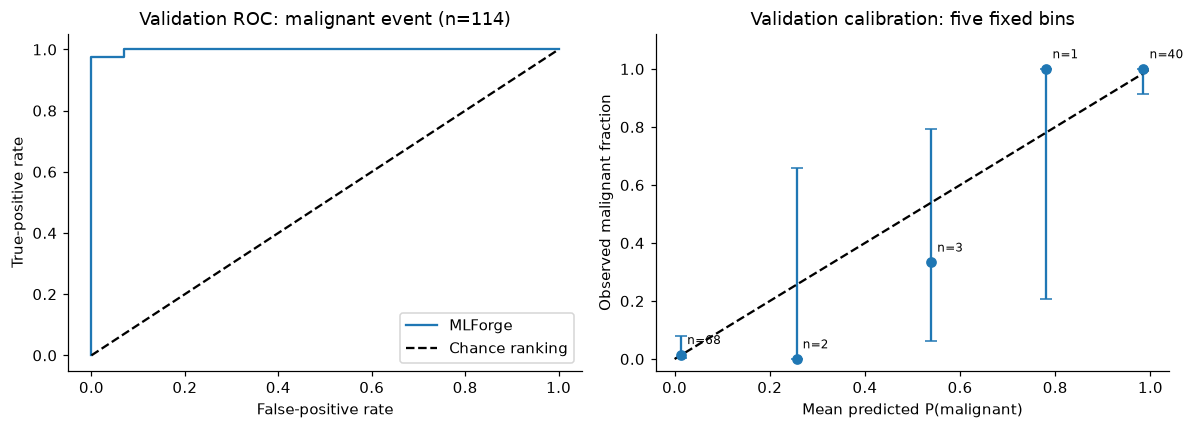

In [4]:
calibration_rows = []
# Fixed-width bins; probability 1 belongs to the final bin.
bin_ids = np.minimum(np.floor(p_event * 5).astype(int), 4)
z95 = NormalDist().inv_cdf(.975)
for bin_id in range(5):
    selected = bin_ids == bin_id
    count = int(selected.sum())
    if count == 0:
        continue
    fraction = float(event_validation[selected].mean())
    denominator = 1 + z95**2/count
    center = (fraction + z95**2/(2*count))/denominator
    half_width = z95*np.sqrt(fraction*(1-fraction)/count + z95**2/(4*count**2))/denominator
    calibration_rows.append({"Bin": bin_id + 1, "Count": count,
        "Mean predicted malignancy": float(p_event[selected].mean()),
        "Observed malignant fraction": fraction,
        "Wilson lower": center-half_width, "Wilson upper": center+half_width})
calibration_table = pd.DataFrame(calibration_rows)
assert calibration_table["Count"].sum() == len(y_validation)
display(calibration_table.round(4))
fpr, tpr, _ = roc_curve(event_validation, p_event)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label="MLForge")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance ranking")
axes[0].set(title=f"Validation ROC: malignant event (n={len(y_validation)})",
            xlabel="False-positive rate", ylabel="True-positive rate")
axes[0].legend()
observed = calibration_table["Observed malignant fraction"].to_numpy()
axes[1].errorbar(calibration_table["Mean predicted malignancy"], observed,
    yerr=np.maximum(0., np.vstack((observed-calibration_table["Wilson lower"],
                                  calibration_table["Wilson upper"]-observed))),
    fmt="o", capsize=4)
for row in calibration_rows:
    axes[1].annotate(f'n={row["Count"]}',
        (row["Mean predicted malignancy"], row["Observed malignant fraction"]),
        xytext=(4, 7), textcoords="offset points", fontsize=8)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set(title="Validation calibration: five fixed bins",
            xlabel="Mean predicted P(malignant)", ylabel="Observed malignant fraction",
            xlim=(-.04, 1.04), ylim=(-.04, 1.12))
fig.tight_layout()
plt.show()

### Prespecified threshold illustration

The thresholds below are fixed teaching examples, not a search for a winner. At threshold $t$, this illustration flags malignancy when `p_event >= t`. Its equality convention is explicit; the package's original `predict` instead assigns a benign probability of exactly 0.5 to benign. None of the validation probabilities is required to be exactly 0.5.

Lower malignant thresholds flag at least as many observations and generally trade fewer missed malignant cases for more false positives. Precision conditions on flagged cases; recall conditions on actual malignant cases. The table retains counts and flags undefined rates with NaN. No threshold is promoted or applied to the existing test set.

In [5]:
threshold_rows = []
for threshold in [.20, .35, .50, .65, .80]:
    flag = (p_event >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(event_validation, flag, labels=[0, 1]).ravel()
    threshold_rows.append({"Malignant threshold": threshold, "TN": tn, "FP": fp,
        "FN": fn, "TP": tp, "Flagged": int(flag.sum()),
        "Malignant recall": tp/(tp+fn) if tp+fn else np.nan,
        "Malignant precision": tp/(tp+fp) if tp+fp else np.nan})
threshold_table = pd.DataFrame(threshold_rows)
assert np.all(threshold_table[["TN", "FP", "FN", "TP"]].sum(axis=1) == len(y_validation))
assert np.all(np.diff(threshold_table["Flagged"]) <= 0)
display(threshold_table.round(4))
print("No threshold selected; the original package decision rule remains unchanged.")

No threshold selected; the original package decision rule remains unchanged.


,Malignant threshold,TN,FP,FN,TP,Flagged,Malignant recall,Malignant precision
0,0.20,67,4,1,42,46,0.9767,0.9130
1,0.35,69,2,1,42,44,0.9767,0.9545
2,0.50,70,1,1,42,43,0.9767,0.9767
3,0.65,71,0,2,41,41,0.9535,1.0000
4,0.80,71,0,3,40,40,0.9302,1.0000


### Interpreting this development experiment

On these 114 validation observations, MLForge log loss is **0.0571** versus **0.6627** for the prevalence baseline; Brier score is **0.0157** versus **0.2349**. ROC AUC is **0.9984**, supporting strong ranking on this small split, not a claim of clinical readiness.

Calibration remains less certain: the three middle bins contain only **2, 3, and 1 observations**. Their wide intervals prevent a strong conclusion about probability accuracy in that region. Strong ranking does not remove that evidence gap.

At malignant thresholds 0.20, 0.50, and 0.80, the model flags **46, 43, and 40** validation observations respectively. The corresponding malignant recalls are **0.9767, 0.9767, and 0.9302**. These fixed examples show the decision tradeoff; no threshold is selected or promoted.

Repeated adaptation to this validation analysis would consume its independence. Future selection must stay inside a prespecified development procedure; stronger final claims need appropriately independent or nested evaluation. This experiment does not create a new untouched test set.

## 3. Expanded five-fold evaluation

The following calculations repeat the original fixed CV settings and add losses,
training scores and explicit split checks. Fresh models and scalers are fitted in
every fold. Assertions verify disjoint partitions, exclusion of outer test rows,
exactly one validation appearance per development row, and training-only scaler
statistics. They check this implemented procedure; random-row independence and
population representativeness remain assumptions.


In [6]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, accuracy_score, mean_squared_error, mean_absolute_error, recall_score, log_loss
from mlforge import LinearRegression, LogisticRegression

RANDOM_STATE = 42
N_FOLDS = 5

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## Part A — Linear Regression on diabetes

We split once into an outer training set (80%) and held-out test set (20%). Then `KFold` rotates the validation group through the 80% training set. Each fold must fit a fresh scaler and a fresh model. The baseline simply predicts the average progression of the fold's training samples.

In [7]:
diabetes = load_diabetes(as_frame=True, scaled=False)
X_d, y_d = diabetes.data, diabetes.target
X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(
    X_d, y_d, test_size=.2, random_state=RANDOM_STATE
)
assert X_d_train.index.is_unique and X_d_test.index.is_unique
assert set(X_d_train.index).isdisjoint(X_d_test.index)
rows_d = []
seen_d = np.zeros(len(X_d_train), dtype=int)
folds_d = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (tr, va) in enumerate(folds_d.split(X_d_train), start=1):
    assert len(np.intersect1d(tr, va)) == 0
    assert set(tr) | set(va) == set(range(len(X_d_train)))
    seen_d[va] += 1
    X_tr, X_va = X_d_train.iloc[tr], X_d_train.iloc[va]
    y_tr, y_va = y_d_train.iloc[tr], y_d_train.iloc[va]
    assert set(X_tr.index).isdisjoint(X_d_test.index)
    assert set(X_va.index).isdisjoint(X_d_test.index)
    scaler = StandardScaler().fit(X_tr)
    assert scaler.n_samples_seen_ == len(tr)
    np.testing.assert_allclose(scaler.mean_, X_tr.mean().to_numpy())
    model = LinearRegression().fit(scaler.transform(X_tr), y_tr)
    training_predictions = model.predict(scaler.transform(X_tr))
    predictions = model.predict(scaler.transform(X_va))
    baseline = np.full(len(y_va), float(y_tr.mean()))
    rows_d.append({"Fold": fold, "Training rows": len(tr), "Validation rows": len(va),
        "Training R²": r2_score(y_tr, training_predictions),
        "MLForge R²": r2_score(y_va, predictions),
        "Mean baseline R²": r2_score(y_va, baseline),
        "Training RMSE": np.sqrt(mean_squared_error(y_tr, training_predictions)),
        "Validation RMSE": np.sqrt(mean_squared_error(y_va, predictions)),
        "Baseline RMSE": np.sqrt(mean_squared_error(y_va, baseline)),
        "Validation MAE": mean_absolute_error(y_va, predictions)})
assert np.all(seen_d == 1), "Every development row must be validated exactly once."
cv_diabetes = pd.DataFrame(rows_d)
display(cv_diabetes.round(4))
print("Diabetes MLForge mean R²:", round(cv_diabetes["MLForge R²"].mean(), 4))
print("Diabetes MLForge SD of R²:", round(cv_diabetes["MLForge R²"].std(ddof=1), 4))

Diabetes MLForge mean R²: 0.4804
Diabetes MLForge SD of R²: 0.0457


,Fold,Training rows,Validation rows,Training R²,MLForge R²,Mean baseline R²,Training RMSE,Validation RMSE,Baseline RMSE,Validation MAE
0,1,282,71,0.5306,0.4701,-0.0718,53.8404,53.3737,75.9112,44.5909
1,2,282,71,0.5174,0.5368,-0.0282,52.9783,56.7610,84.5688,48.2776
2,3,282,71,0.5451,0.4111,-0.0008,53.9673,53.0431,69.1466,42.9260
3,4,283,70,0.5313,0.4913,-0.0255,53.5033,54.4600,77.3241,44.3011
4,5,283,70,0.5298,0.4925,-0.0103,52.4412,59.3353,83.7175,45.1452


## Part B — Logistic Regression on breast cancer

Use `StratifiedKFold` because we want each validation group to contain similar proportions of malignant (`0`) and benign (`1`) examples. The baseline always guesses the most frequent class of that round's training group.

In [8]:
cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_c, y_c, test_size=.2, random_state=RANDOM_STATE, stratify=y_c
)
assert X_c_train.index.is_unique and X_c_test.index.is_unique
assert set(X_c_train.index).isdisjoint(X_c_test.index)
rows_c = []
seen_c = np.zeros(len(X_c_train), dtype=int)
folds_c = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (tr, va) in enumerate(folds_c.split(X_c_train, y_c_train), start=1):
    assert len(np.intersect1d(tr, va)) == 0
    assert set(tr) | set(va) == set(range(len(X_c_train)))
    seen_c[va] += 1
    X_tr, X_va = X_c_train.iloc[tr], X_c_train.iloc[va]
    y_tr, y_va = y_c_train.iloc[tr], y_c_train.iloc[va]
    assert set(X_tr.index).isdisjoint(X_c_test.index)
    assert set(X_va.index).isdisjoint(X_c_test.index)
    assert set(y_tr.unique()) == {0, 1} and set(y_va.unique()) == {0, 1}
    scaler = StandardScaler().fit(X_tr)
    assert scaler.n_samples_seen_ == len(tr)
    np.testing.assert_allclose(scaler.mean_, X_tr.mean().to_numpy())
    model = LogisticRegression(learning_rate=.1, max_iter=2000).fit(scaler.transform(X_tr), y_tr)
    predictions = model.predict(scaler.transform(X_va))
    training_predictions = model.predict(scaler.transform(X_tr))
    p_malignant = model.predict_proba(scaler.transform(X_va))[:, 0]
    event = (y_va.to_numpy() == 0).astype(int)
    majority_label = int(y_tr.value_counts().idxmax())
    baseline = np.full(len(y_va), majority_label)
    baseline_probability = np.full(len(y_va), float((y_tr == 0).mean()))
    rows_c.append({"Fold": fold, "Training rows": len(tr), "Validation rows": len(va),
        "Training accuracy": accuracy_score(y_tr, training_predictions),
        "MLForge accuracy": accuracy_score(y_va, predictions),
        "Majority baseline accuracy": accuracy_score(y_va, baseline),
        "Malignant recall": recall_score(y_va, predictions, pos_label=0),
        "Validation log loss": log_loss(event, p_malignant, labels=[0, 1]),
        "Prevalence baseline log loss": log_loss(event, baseline_probability, labels=[0, 1])})
assert np.all(seen_c == 1), "Every development row must be validated exactly once."
cv_cancer = pd.DataFrame(rows_c)
display(cv_cancer.round(4))
print("Cancer MLForge mean accuracy:", round(cv_cancer["MLForge accuracy"].mean(), 4))
print("Cancer MLForge SD of accuracy:", round(cv_cancer["MLForge accuracy"].std(ddof=1), 4))
display(pd.DataFrame({"Dataset": ["Diabetes", "Breast Cancer"],
    "Outer development rows": [len(X_d_train), len(X_c_train)],
    "Outer test rows (excluded from CV)": [len(X_d_test), len(X_c_test)],
    "Validation folds": [N_FOLDS, N_FOLDS]}).set_index("Dataset"))

Cancer MLForge mean accuracy: 0.978
Cancer MLForge SD of accuracy: 0.011


,Fold,Training rows,Validation rows,Training accuracy,MLForge accuracy,Majority baseline accuracy,Malignant recall,Validation log loss,Prevalence baseline log loss
0,1,364,91,0.989,0.967,0.6264,0.9118,0.1260,0.6609
1,2,364,91,0.989,0.989,0.6264,1.0000,0.0413,0.6609
2,3,364,91,0.989,0.978,0.6264,0.9706,0.0663,0.6609
3,4,364,91,0.989,0.989,0.6264,0.9706,0.0548,0.6609
4,5,364,91,0.989,0.967,0.6264,0.9706,0.0542,0.6609


,Outer development rows,Outer test rows (excluded from CV),Validation folds
Dataset,,,
Diabetes,353,89,5
Breast Cancer,455,114,5


## Part C — Mean, variation, and training/validation gaps

A fold is a categorical partition, not a time point. Points below show validation evidence alongside training-only baselines. The tables retain each fold's training and validation sample counts. Scores for the two tasks use different scales and must not be compared directly.

We report unweighted means and sample standard deviations (`ddof=1`) across five folds. Diabetes folds differ by one validation row, so these are fold averages rather than pooled-observation metrics. Training sets overlap: fold SD is **not a confidence interval or an independent-replicate standard error**. The split assumes exchangeable rows within these teaching datasets; it does not evaluate transfer across hospitals or time.

Regression: mean and sample fold SD
Classification: mean and sample fold SD
Validation R² range: 0.4111–0.5368
Validation accuracy range: 0.9670–0.9890
Mean regression train-minus-validation R² gap: 0.0505
Mean classifier train-minus-validation accuracy gap: 0.0110


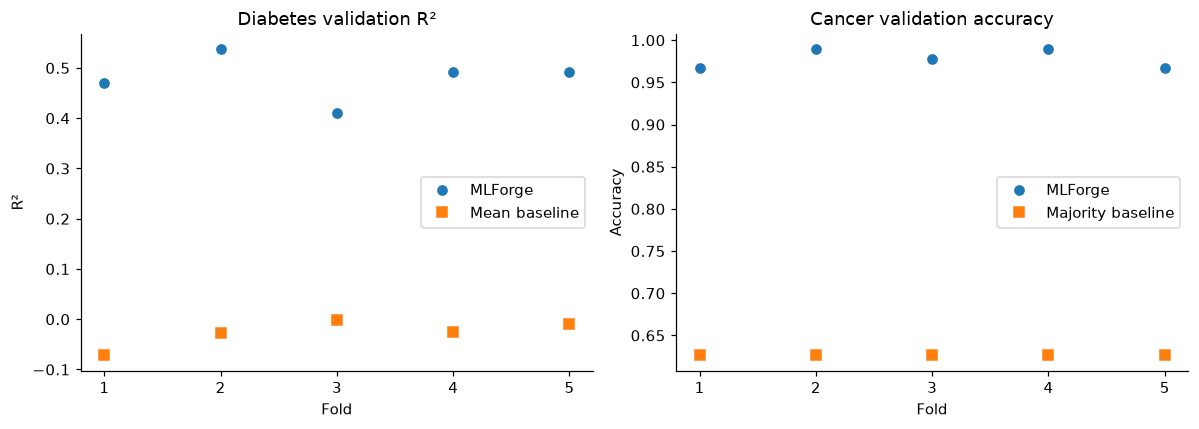

,mean,std
Training R²,0.5308,0.0098
MLForge R²,0.4804,0.0457
Mean baseline R²,-0.0273,0.0273
Training RMSE,53.3461,0.6342
Validation RMSE,55.3946,2.6402
Baseline RMSE,78.1336,6.3038
Validation MAE,45.0482,1.9818


,mean,std
Training accuracy,0.9890,0.0000
MLForge accuracy,0.9780,0.0110
Majority baseline accuracy,0.6264,0.0000
Malignant recall,0.9647,0.0322
Validation log loss,0.0685,0.0333
Prevalence baseline log loss,0.6609,0.0000


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cv_diabetes["Fold"], cv_diabetes["MLForge R²"], marker="o", linestyle="none", label="MLForge")
axes[0].plot(cv_diabetes["Fold"], cv_diabetes["Mean baseline R²"], marker="s", linestyle="none", label="Mean baseline")
axes[0].set(title="Diabetes validation R²", xlabel="Fold", ylabel="R²", xticks=range(1, 6))
axes[0].legend()
axes[1].plot(cv_cancer["Fold"], cv_cancer["MLForge accuracy"], marker="o", linestyle="none", label="MLForge")
axes[1].plot(cv_cancer["Fold"], cv_cancer["Majority baseline accuracy"], marker="s", linestyle="none", label="Majority baseline")
axes[1].set(title="Cancer validation accuracy", xlabel="Fold", ylabel="Accuracy", xticks=range(1, 6))
axes[1].legend()
fig.tight_layout()
plt.show()

assert len(cv_diabetes) == N_FOLDS and len(cv_cancer) == N_FOLDS
assert np.all(np.isfinite(cv_diabetes.select_dtypes(include="number")))
assert np.all(np.isfinite(cv_cancer.select_dtypes(include="number")))

regression_columns = ["Training R²", "MLForge R²", "Mean baseline R²", "Training RMSE", "Validation RMSE", "Baseline RMSE", "Validation MAE"]
classification_columns = ["Training accuracy", "MLForge accuracy", "Majority baseline accuracy", "Malignant recall", "Validation log loss", "Prevalence baseline log loss"]
print("Regression: mean and sample fold SD")
display(cv_diabetes[regression_columns].agg(["mean", "std"]).T.round(4))
print("Classification: mean and sample fold SD")
display(cv_cancer[classification_columns].agg(["mean", "std"]).T.round(4))
print(f"Validation R² range: {cv_diabetes['MLForge R²'].min():.4f}–{cv_diabetes['MLForge R²'].max():.4f}")
print(f"Validation accuracy range: {cv_cancer['MLForge accuracy'].min():.4f}–{cv_cancer['MLForge accuracy'].max():.4f}")
print(f"Mean regression train-minus-validation R² gap: {(cv_diabetes['Training R²']-cv_diabetes['MLForge R²']).mean():.4f}")
print(f"Mean classifier train-minus-validation accuracy gap: {(cv_cancer['Training accuracy']-cv_cancer['MLForge accuracy']).mean():.4f}")

## Findings, limits, and project synthesis

The fixed Linear Regression configuration has validation R² approximately **0.411–0.537** across these five folds; the classifier's validation accuracy is approximately **0.967–0.989**. Both beat their constant-label/constant-mean baselines in the displayed folds. Target-unit errors, malignant recall, and probability loss describe behavior that R² and accuracy alone omit.

Compare the displayed training and validation means to identify optimism, but do not treat a gap as proof of a particular cause. Small fold variation is evidence about this split scheme, not a guarantee on future populations. Neither model supports causal or clinical claims.

Together the notebooks demonstrate: (1) training-only exploration and scaling; (2) stable least squares with residual evidence; (3) binary probability modeling with explicit event semantics; and (4) validation variation with partition assertions. The package separates reusable implementations from experiments, while mathematical tests protect their behavior.

**Next justified experiment:** predeclare a question and evaluation procedure using development data. Do not use the already-viewed holdout to select settings. This revision adds no third algorithm, regularization, or threshold selection.

Textbook links: supervised-learning contract (Chapter 11), classification evidence (Chapter 14), honest model selection and dependent fold scores (Chapter 24).